# Online Retail – Exploratory Data Analysis (Time Series)
Nishant · TECH 405

Daily UK revenue, built from the UCI Online Retail transactions, analysed for the mandatory
checks plus the time-series track.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)


**Dataset card.** UCI Machine Learning Repository – Online Retail Data Set. Licence: CC BY 4.0.
~23.7 MB on disk, 541,909 transaction line-items across 8 columns (`InvoiceNo`, `StockCode`,
`Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`). Real transactions
from a UK-based online gift retailer, 01 Dec 2010 – 09 Dec 2011, one row per product line per
invoice. Limitations: `CustomerID` missing for ~25% of rows; only one calendar year of data, so
year-over-year seasonality can't be checked; 91% of revenue is from the UK out of 38 countries.


In [ ]:
# Upload the dataset from your computer (a Colab file picker will pop up --
# choose "Online Retail.xlsx" from your Downloads folder).
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]


In [2]:
df = pd.read_excel(filename)
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
df.sample(5, random_state=42)


Shape: (541909, 8)

Dtypes:
 InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


In [3]:
# Missing, duplicate, and corrupt entries.
# "Corrupt" here = negative/zero Quantity on a non-cancellation invoice, UnitPrice <= 0
# (postage/adjustment lines), or cancellation invoices (InvoiceNo starts with 'C').
missing = df.isnull().sum()
dupes = df.duplicated().sum()
cancelled = df['InvoiceNo'].astype(str).str.startswith('C').sum()
neg_qty_noncancel = ((df['Quantity'] < 0) & (~df['InvoiceNo'].astype(str).str.startswith('C'))).sum()
non_positive_price = (df['UnitPrice'] <= 0).sum()

print("Missing values per column:\n", missing[missing > 0])
print("\nExact duplicate rows:", dupes)
print("Cancellation invoices (InvoiceNo starts with 'C'):", cancelled)
print("Negative quantity on NON-cancellation invoices (likely data error):", neg_qty_noncancel)
print("Rows with UnitPrice <= 0:", non_positive_price)


Missing values per column:
 Description      1454
CustomerID     135080
dtype: int64

Exact duplicate rows: 5268
Cancellation invoices (InvoiceNo starts with 'C'): 9288
Negative quantity on NON-cancellation invoices (likely data error): 1336
Rows with UnitPrice <= 0: 2517


In [4]:
# Decisions: drop exact duplicates; keep cancellations as a flag rather than deleting them
# (excluded only when computing revenue); drop UnitPrice <= 0 from revenue (not product sales);
# leave missing CustomerID as-is since it isn't used for a daily revenue series.
df = df.drop_duplicates().copy()
df['is_cancelled'] = df['InvoiceNo'].astype(str).str.startswith('C')
df['Revenue'] = df['Quantity'] * df['UnitPrice']
print("Shape after de-duplication:", df.shape)


Shape after de-duplication: (536641, 10)


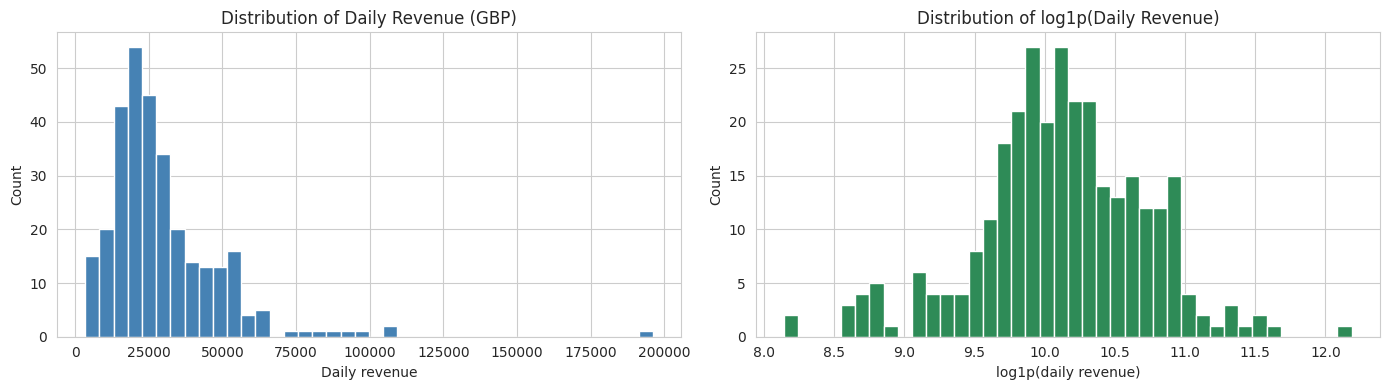

Skewness (raw): 3.02
Skewness (log1p): -0.25


In [5]:
# Target distribution. Target = daily total UK revenue (continuous, so no class imbalance --
# we instead check the shape of the distribution to decide on a transform).
uk = df[(df['Country'] == 'United Kingdom') & (~df['is_cancelled']) & (df['UnitPrice'] > 0)].copy()
daily = uk.set_index('InvoiceDate').resample('D')['Revenue'].sum()
daily = daily[daily > 0]  # drop days with literally no recorded sales (store closed)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(daily, bins=40, color='steelblue')
axes[0].set_title('Distribution of Daily Revenue (GBP)')
axes[0].set_xlabel('Daily revenue'); axes[0].set_ylabel('Count')

axes[1].hist(np.log1p(daily), bins=40, color='seagreen')
axes[1].set_title('Distribution of log1p(Daily Revenue)')
axes[1].set_xlabel('log1p(daily revenue)'); axes[1].set_ylabel('Count')
plt.tight_layout()
plt.savefig('target_distribution.png', dpi=120)
plt.show()

print("Skewness (raw):", daily.skew().round(2))
print("Skewness (log1p):", np.log1p(daily).skew().round(2))


Raw daily revenue is right-skewed (a few very high-revenue days near Christmas), which would
let the LSTM's loss get dominated by a handful of spikes. `log1p` reduces this skew and will be
the model's working target, transformed back via `expm1` at inference time.

**Split plan:** chronological, no shuffling — train Dec 2010–Aug 2011 (~75%), validation
Sep–Oct 2011 (~15%), test Nov–9 Dec 2011 (~10%, includes the pre-Christmas peak). A random or
stratified split would leak future information into training for a forecasting problem, so the
model must only ever be validated on days after everything it was trained on.


In [6]:
train_end = '2011-08-31'
val_end = '2011-10-31'

train = daily[:train_end]
val = daily[train_end:val_end][1:]
test = daily[val_end:][1:]

print(f"Train: {train.index.min().date()} -> {train.index.max().date()}  ({len(train)} days)")
print(f"Val:   {val.index.min().date()} -> {val.index.max().date()}  ({len(val)} days)")
print(f"Test:  {test.index.min().date()} -> {test.index.max().date()}  ({len(test)} days)")


Train: 2010-12-01 -> 2011-08-31  (219 days)
Val:   2011-09-01 -> 2011-10-31  (52 days)
Test:  2011-11-01 -> 2011-12-09  (34 days)


**Three findings that change model design:**
1. Near-zero Sunday sales (see chart below) — weekday should be an explicit input feature, or
   the LSTM will partly learn a weekday calendar instead of genuine demand.
2. Volume ramps sharply in the final six weeks before Christmas — a model trained mostly on
   flatter months will under-predict this unless trend/seasonality is decomposed out or given as
   a feature.
3. A handful of days are dominated by single bulk wholesale orders — cap/winsorise these rather
   than delete them, so the LSTM doesn't treat one bulk order as the series' normal scale.


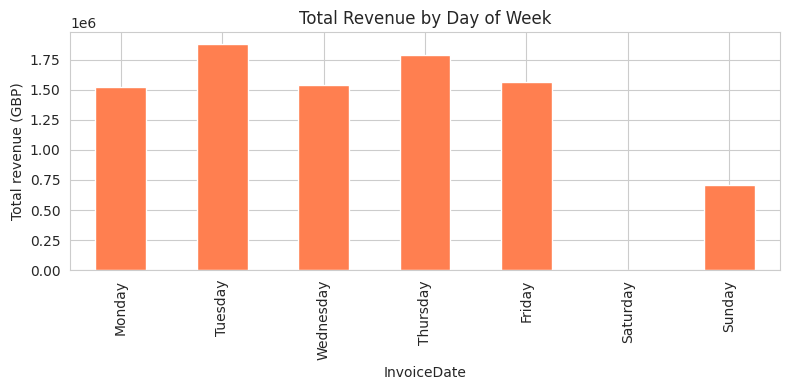

In [7]:
by_weekday = daily.groupby(lambda d: d.day_name()).sum()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
by_weekday.reindex(order).plot(kind='bar', color='coral', figsize=(8,4), title='Total Revenue by Day of Week')
plt.ylabel('Total revenue (GBP)')
plt.tight_layout()
plt.savefig('revenue_by_weekday.png', dpi=120)
plt.show()


---
**Time series track** — everything below uses the daily UK revenue series (`daily`) built above.


Calendar days in range: 374
Days with recorded sales: 305
Missing/zero-sales days: 69
Sample missing dates: [datetime.date(2010, 12, 4), datetime.date(2010, 12, 11), datetime.date(2010, 12, 18), datetime.date(2010, 12, 24), datetime.date(2010, 12, 25), datetime.date(2010, 12, 26), datetime.date(2010, 12, 27), datetime.date(2010, 12, 28), datetime.date(2010, 12, 29), datetime.date(2010, 12, 30)]


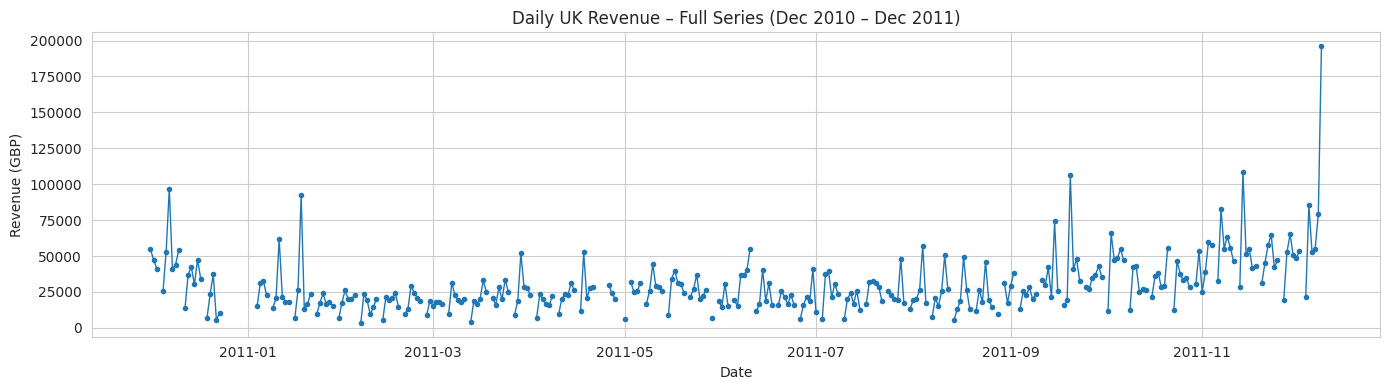


IQR outlier days: 10


InvoiceDate
2011-12-09    196114.48
2011-11-14    108397.45
2011-09-20    106593.32
2010-12-07     96796.28
2011-01-18     92396.96
Name: Revenue, dtype: float64

In [8]:
# Full series, gaps, and outliers.
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq='D')
missing_days = full_range.difference(daily.index)
print(f"Calendar days in range: {len(full_range)}")
print(f"Days with recorded sales: {len(daily)}")
print(f"Missing/zero-sales days: {len(missing_days)}")
print("Sample missing dates:", list(missing_days[:10].date))

daily_full = daily.reindex(full_range)  # reintroduce gaps as NaN to see them clearly

plt.figure(figsize=(14,4))
plt.plot(daily_full.index, daily_full.values, marker='.', linewidth=1)
plt.title('Daily UK Revenue – Full Series (Dec 2010 – Dec 2011)')
plt.xlabel('Date'); plt.ylabel('Revenue (GBP)')
plt.tight_layout()
plt.savefig('full_series.png', dpi=120)
plt.show()

q1, q3 = daily.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = daily[(daily < q1 - 1.5*iqr) | (daily > q3 + 1.5*iqr)]
print(f"\nIQR outlier days: {len(outliers)}")
outliers.sort_values(ascending=False).head(5)


Gaps are mostly Sundays and UK bank holidays (Christmas, Boxing Day, New Year's) when the
store made no sales, plus a few IQR outlier days from single large invoices. Gaps will be
zero-filled explicitly before windowing.


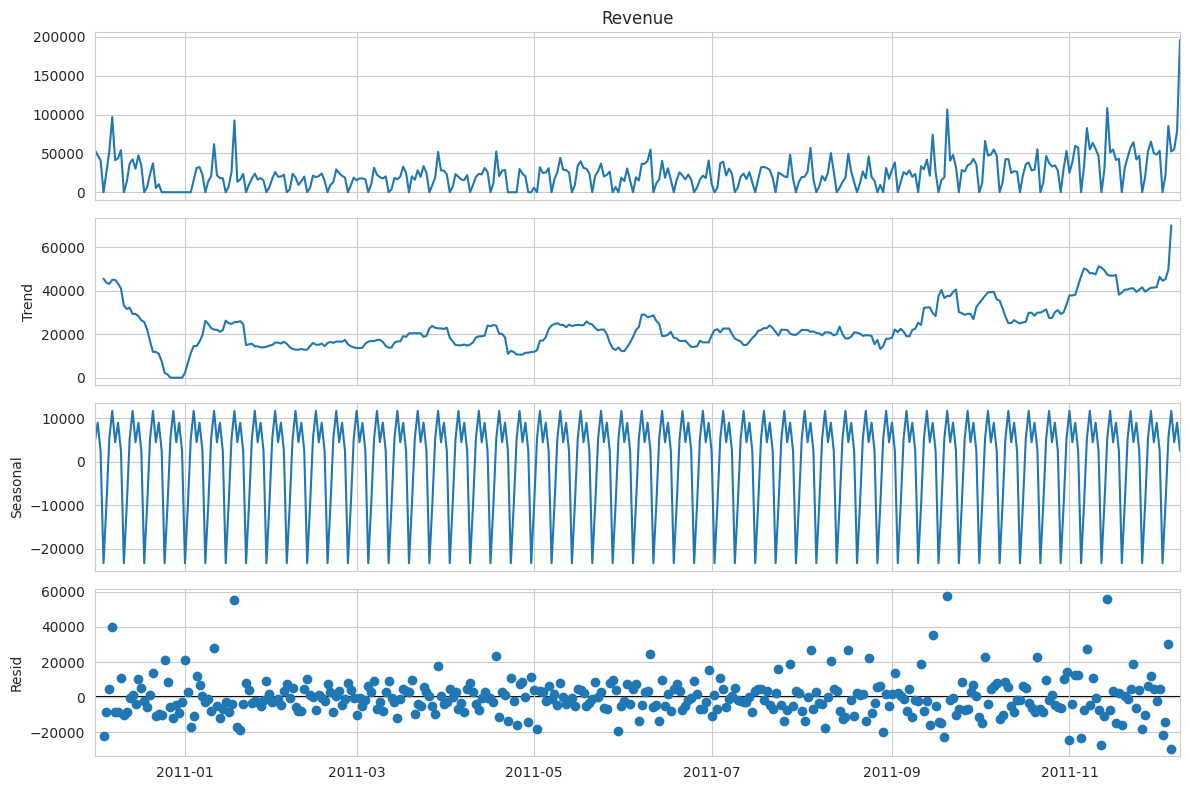

In [9]:
# Seasonal decomposition and autocorrelation.
daily_filled = daily.reindex(full_range).fillna(0)
daily_filled.index.freq = 'D'

decomposition = seasonal_decompose(daily_filled, model='additive', period=7)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.savefig('seasonal_decompose.png', dpi=120)
plt.show()


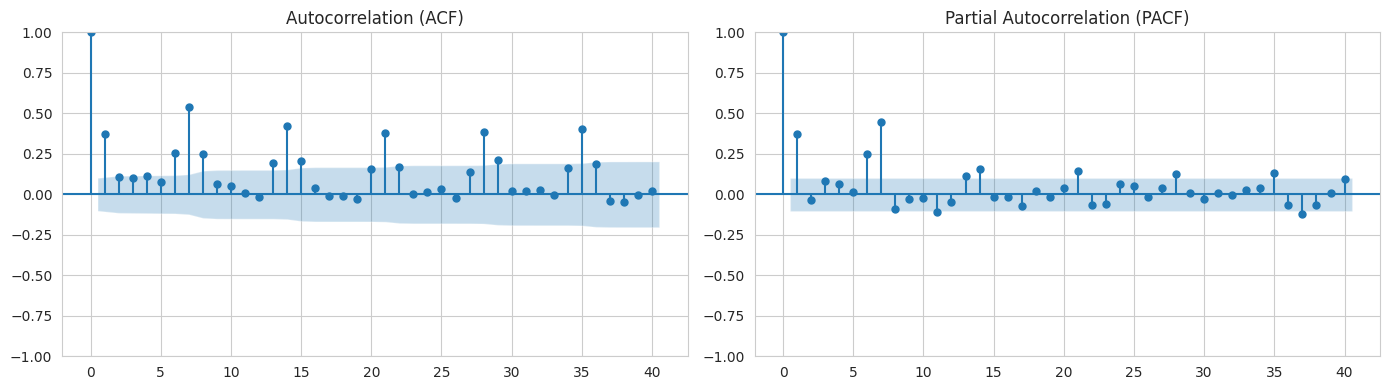

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))
plot_acf(daily_filled, lags=40, ax=axes[0])
axes[0].set_title('Autocorrelation (ACF)')
plot_pacf(daily_filled, lags=40, ax=axes[1])
axes[1].set_title('Partial Autocorrelation (PACF)')
plt.tight_layout()
plt.savefig('acf_pacf.png', dpi=120)
plt.show()


Clear 7-day (weekly) seasonality, troughing on Sundays, layered on a trend rising into the
Nov–Dec peak. ACF shows a strong spike at lag 7 and its multiples (14, 21) — genuine weekly
seasonality, not noise.


In [11]:
# Stationarity check (ADF test).
result_raw = adfuller(daily_filled)
print("ADF on raw daily revenue:")
print(f"  ADF statistic: {result_raw[0]:.3f}   p-value: {result_raw[1]:.4f}")

daily_diff = daily_filled.diff(7).dropna()  # seasonal differencing at lag 7
result_diff = adfuller(daily_diff)
print("\nADF on 7-day seasonally-differenced revenue:")
print(f"  ADF statistic: {result_diff[0]:.3f}   p-value: {result_diff[1]:.4f}")


ADF on raw daily revenue:
  ADF statistic: -0.394   p-value: 0.9111

ADF on 7-day seasonally-differenced revenue:
  ADF statistic: -5.349   p-value: 0.0000


/tmp/ipykernel_97/1337302855.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_raw = adfuller(daily_filled)
/tmp/ipykernel_97/1337302855.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result_diff = adfuller(daily_diff)


Raw series: high ADF p-value → can't reject a unit root → non-stationary, consistent with
the trend + seasonality above. After 7-day seasonal differencing, p-value drops well below 0.05
→ stationary. **Transform to apply:** `log1p`, then 7-day seasonal differencing, before the LSTM.


In [12]:
# LSTM window length, justified from the ACF.
acf_vals = acf(daily_filled, nlags=40)
significant_lags = [lag for lag, v in enumerate(acf_vals) if lag > 0 and abs(v) > 1.96/np.sqrt(len(daily_filled))]
print("Statistically significant lags (95% CI):", significant_lags[:15])


Statistically significant lags (95% CI): [1, 2, 4, 6, 7, 8, 13, 14, 15, 20, 21, 22, 27, 28, 29]


**Chosen window length: 14 days.** ACF/PACF are strongest and most consistent at lag 7 and
its second harmonic at lag 14, then get noisy — 14 days gives the LSTM two full weekly cycles of
context without pulling in an unrelated month-old trend level (already removed by differencing).

---
**Summary:** clean but non-stationary, weekly-seasonal daily revenue with a rising trend into
Christmas. Next assignment's LSTM will use log1p + 7-day seasonal differencing, a 14-day input
window, and the chronological train/val/test split defined above.
